# 80 · Flow matching from scratch: the two-mode dataset, the velocity field and its seam, counting modes

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

torch.manual_seed(0)

def sample_data(n):
    left = torch.randn(n // 2, 2) * 0.3 + torch.tensor([-2.0, 0.0])
    right = torch.randn(n - n // 2, 2) * 0.3 + torch.tensor([2.0, 0.0])
    return torch.cat([left, right], 0)

class VelocityField(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))
    def forward(self, a, tau):
        return self.net(torch.cat([a, tau], -1))

@torch.no_grad()
def sample(model, n=100, n_steps=10, keep=False):
    a, path = torch.randn(n, 2), []
    for k in range(n_steps):
        tau = torch.full((n, 1), k / n_steps)
        a = a + model(a, tau) / n_steps
        path.append(a.clone())
    return (a, path) if keep else a

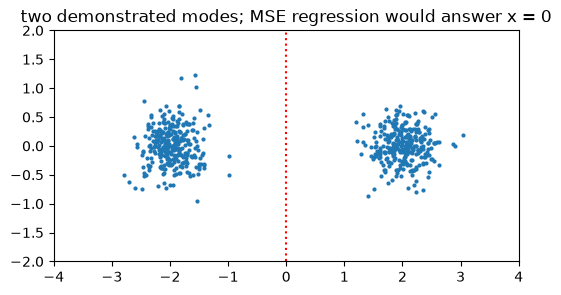

In [2]:
x = sample_data(600)
plt.figure(figsize=(6, 3)); plt.scatter(*x.T, s=4); plt.axvline(0, c="r", ls=":"); plt.title("two demonstrated modes; MSE regression would answer x = 0")
plt.xlim(-4, 4); plt.ylim(-2, 2); plt.show()

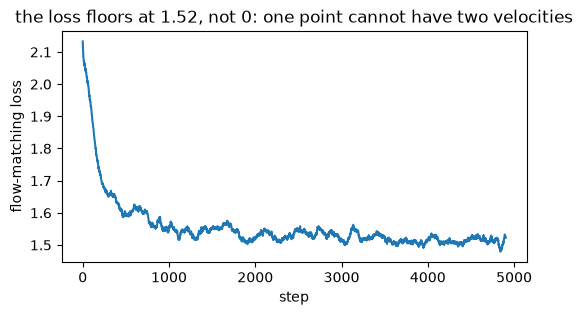

In [3]:
model = VelocityField(); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []
for step in range(5000):
    a1 = sample_data(256); a0 = torch.randn_like(a1); tau = torch.rand(a1.shape[0], 1)
    a_tau = (1 - tau) * a0 + tau * a1
    loss = ((model(a_tau, tau) - (a1 - a0)) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(100) / 100, "valid")); plt.ylabel("flow-matching loss"); plt.xlabel("step")
plt.title(f"the loss floors at {np.mean(losses[-500:]):.2f}, not 0: one point cannot have two velocities"); plt.show()

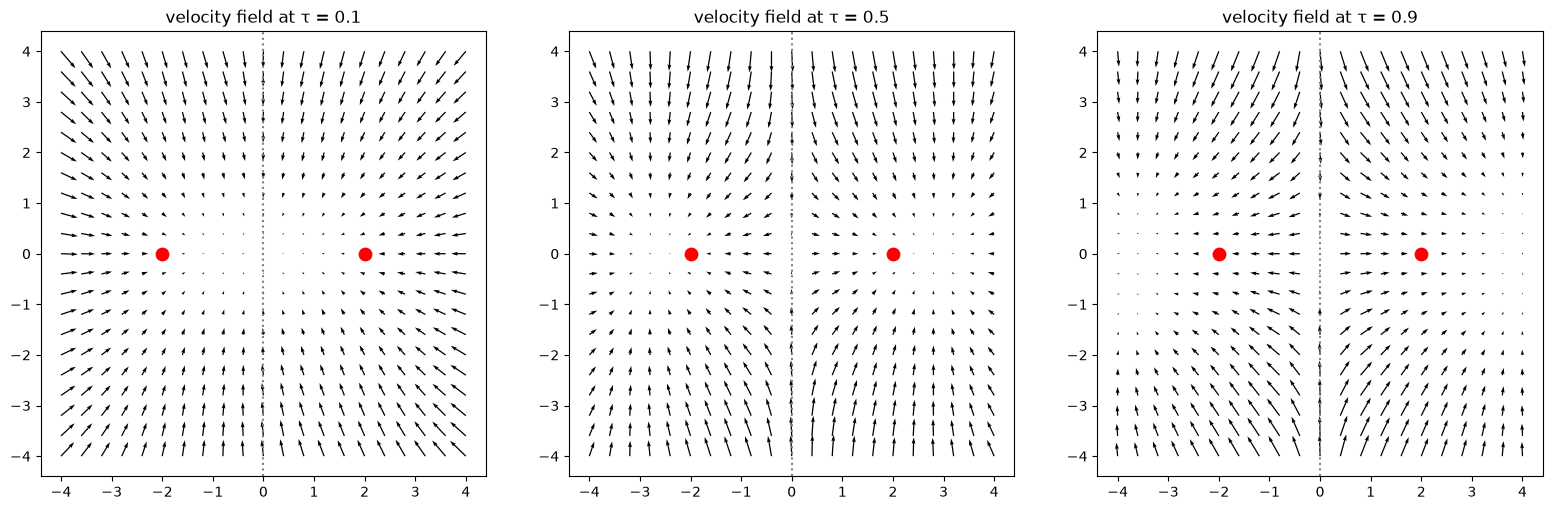

In [4]:
xs = torch.linspace(-4, 4, 21); gx, gy = torch.meshgrid(xs, xs, indexing="xy")
grid = torch.stack([gx.reshape(-1), gy.reshape(-1)], -1)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, t in zip(axes, [0.1, 0.5, 0.9]):
    with torch.no_grad():
        v = model(grid, torch.full((grid.shape[0], 1), t))
    ax.quiver(grid[:, 0], grid[:, 1], v[:, 0], v[:, 1]); ax.scatter([-2, 2], [0, 0], c="red", s=80, zorder=3)
    ax.axvline(0, c="gray", ls=":"); ax.set_title(f"velocity field at τ = {t}"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

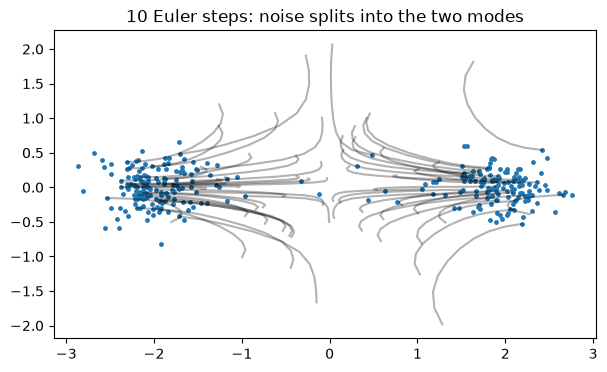

left mode 0.51 | right mode 0.46 | in the middle (would be a bad action) 0.03


In [5]:
final, path = sample(model, n=300, n_steps=10, keep=True)
fig, ax = plt.subplots(figsize=(7, 4))
P = torch.stack(path)
for i in range(60):
    ax.plot(P[:, i, 0], P[:, i, 1], "k-", alpha=0.3)
ax.scatter(*final.T, s=6, c="tab:blue"); ax.set_title("10 Euler steps: noise splits into the two modes"); plt.show()
left, right, middle = (final[:, 0] < -1).float().mean(), (final[:, 0] > 1).float().mean(), (final[:, 0].abs() < 1).float().mean()
print(f"left mode {left:.2f} | right mode {right:.2f} | in the middle (would be a bad action) {middle:.2f}")

In [6]:
for steps in [1, 2, 5, 10, 50]:
    f = sample(model, 2000, steps)
    print(f"{steps:3d} Euler steps: fraction in the middle {(f[:, 0].abs() < 1).float().mean():.3f}, mode std {f[f[:, 0] > 0].std(0).mean():.2f} (data 0.30)")

  1 Euler steps: fraction in the middle 1.000, mode std 0.11 (data 0.30)
  2 Euler steps: fraction in the middle 0.515, mode std 0.35 (data 0.30)
  5 Euler steps: fraction in the middle 0.075, mode std 0.32 (data 0.30)
 10 Euler steps: fraction in the middle 0.021, mode std 0.29 (data 0.30)
 50 Euler steps: fraction in the middle 0.007, mode std 0.31 (data 0.30)
